# FedVocabHAR RealWorld HAR Phase 3A

## Independent dataset acquisition, audit, and preregistration

This notebook prepares the independent RealWorld HAR validation dataset without training or selecting a model. It downloads only official accelerometer and gyroscope CSV archives, extracts the forearm sensor position, resamples every recording to 50 Hz, creates fixed 128-sample windows with 50% overlap, and saves accelerometer-only and accelerometer-plus-gyroscope caches.

The activity vocabulary, five subject-group outer folds, performance gates, and Phase 2E recipe are written to a manifest before data processing. They must not be changed after viewing external test results.

Official source: https://www.uni-mannheim.de/dws/research/projects/activity-recognition/dataset/dataset-realworld/


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from pathlib import Path
from io import BytesIO
import hashlib,json,os,re,shutil,time,warnings,zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    official_base:str='https://www.uni-mannheim.de/media/Einrichtungen/dws/Files_Research/Projects/sensor/realworld'
    subjects:tuple=tuple(range(1,16))
    activities:tuple=('walking','running','sitting','standing','lying','climbingup','climbingdown','jumping')
    known_activities:tuple=('walking','running','sitting','standing')
    novel_activities:tuple=('climbingup','climbingdown','jumping','lying')
    sensors:tuple=('acc','gyr')
    position:str='forearm'
    target_hz:int=50
    window_size:int=128
    stride:int=64
    minimum_windows_per_subject_activity:int=25
    request_timeout_seconds:int=180
    request_retries:int=4
    known_accuracy_gate:float=.60
    known_macro_f1_gate:float=.50
    worst_known_f1_gate:float=.40
    novel_macro_f1_gate:float=.65
    worst_novel_f1_gate:float=.40
    combined_macro_f1_gate:float=.45
    cross_subject_sd_gate:float=.12

CFG=Config();PROJECT=Path(CFG.project);DATA=PROJECT/'data'/'realworld';RAW=DATA/'raw';CACHE=DATA/'cache';OUT=PROJECT/'artifacts'/'phase3a'
for path in (RAW,CACHE,OUT):path.mkdir(parents=True,exist_ok=True)
print(json.dumps(asdict(CFG),indent=2));print('free /content GB:',round(shutil.disk_usage('/content').free/2**30,2))


{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "official_base": "https://www.uni-mannheim.de/media/Einrichtungen/dws/Files_Research/Projects/sensor/realworld",
  "subjects": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15
  ],
  "activities": [
    "walking",
    "running",
    "sitting",
    "standing",
    "lying",
    "climbingup",
    "climbingdown",
    "jumping"
  ],
  "known_activities": [
    "walking",
    "running",
    "sitting",
    "standing"
  ],
  "novel_activities": [
    "climbingup",
    "climbingdown",
    "jumping",
    "lying"
  ],
  "sensors": [
    "acc",
    "gyr"
  ],
  "position": "forearm",
  "target_hz": 50,
  "window_size": 128,
  "stride": 64,
  "minimum_windows_per_subject_activity": 25,
  "request_timeout_seconds": 180,
  "request_retries": 4,
  "known_accuracy_gate": 0.6,
  "known_macro_f1_gate": 0.5,
  "worst_known_f1_gate": 0.4,
  "novel_macro_f1_gate": 0.65,
  "worst_novel_f1_gat

## Preregistered vocabulary, folds, and frozen method

The five outer folds contain three unseen subjects each. Within each fold, the remaining twelve subjects are deterministically divided into six encoder-training clients, three checkpoint-selection clients, and three unlabeled integration clients. The split manifest is saved before any archive is downloaded.


In [3]:
OUTER_TEST=((1,6,11),(2,7,12),(3,8,13),(4,9,14),(5,10,15))
folds=[]
for fold_id,test in enumerate(OUTER_TEST,1):
    remaining=[s for s in CFG.subjects if s not in test];offset=(2*(fold_id-1))%len(remaining);rotated=remaining[offset:]+remaining[:offset]
    folds.append({'fold':fold_id,'train_subjects':rotated[:6],'selection_subjects':rotated[6:9],
                  'integration_subjects':rotated[9:12],'test_subjects':list(test)})
for fold in folds:
    roles=[set(fold[k]) for k in ('train_subjects','selection_subjects','integration_subjects','test_subjects')]
    assert set.union(*roles)==set(CFG.subjects)
    assert all(roles[i].isdisjoint(roles[j]) for i in range(len(roles)) for j in range(i+1,len(roles)))

preregistration={
 'dataset':'RealWorld HAR 2016','official_source':'https://www.uni-mannheim.de/dws/research/projects/activity-recognition/dataset/dataset-realworld/',
 'primary_modality':'forearm accelerometer XYZ plus magnitude','secondary_modality':'forearm accelerometer XYZ plus magnitude and gyroscope XYZ',
 'known_activities':list(CFG.known_activities),'novel_activities':list(CFG.novel_activities),'outer_folds':folds,
 'frozen_method':{'initialization':'label-free SSL-Full trained within each outer fold','adaptation':'cross-subject Episodic Anchor',
                  'anchor_weight':.25,'prototype_temperature':.10,'support_per_class':8,'query_per_class':12,
                  'episodes_per_epoch':36,'epochs':20,'selection_rule':'development prototype geometry only'},
 'gates':{k:v for k,v in asdict(CFG).items() if k.endswith('_gate')},
 'rule':'No fold, vocabulary, hyperparameter, or gate may be changed after external test results are opened.'}
(OUT/'phase3a_preregistered_manifest.json').write_text(json.dumps(preregistration,indent=2))
print(json.dumps(preregistration,indent=2))


{
  "dataset": "RealWorld HAR 2016",
  "official_source": "https://www.uni-mannheim.de/dws/research/projects/activity-recognition/dataset/dataset-realworld/",
  "primary_modality": "forearm accelerometer XYZ plus magnitude",
  "secondary_modality": "forearm accelerometer XYZ plus magnitude and gyroscope XYZ",
  "known_activities": [
    "walking",
    "running",
    "sitting",
    "standing"
  ],
  "novel_activities": [
    "climbingup",
    "climbingdown",
    "jumping",
    "lying"
  ],
  "outer_folds": [
    {
      "fold": 1,
      "train_subjects": [
        2,
        3,
        4,
        5,
        7,
        8
      ],
      "selection_subjects": [
        9,
        10,
        12
      ],
      "integration_subjects": [
        13,
        14,
        15
      ],
      "test_subjects": [
        1,
        6,
        11
      ]
    },
    {
      "fold": 2,
      "train_subjects": [
        4,
        5,
        6,
        8,
        9,
        10
      ],
      "selection_s

## Resumable official-source download

Each URL points to the University of Mannheim archive for one subject, activity, and sensor. Existing nonempty archives are reused. Failed downloads are retried and recorded; processing does not silently omit a subject or activity.


In [4]:
def archive_url(subject,activity,sensor):
    return f'{CFG.official_base}/s{subject}/data/{sensor}_{activity}_csv.zip'

def sha256(path,chunk=2**20):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        while True:
            data=stream.read(chunk)
            if not data:break
            h.update(data)
    return h.hexdigest()

def download(url,destination):
    if destination.exists() and destination.stat().st_size>100:
        try:
            with zipfile.ZipFile(destination) as z:z.testzip()
            return 'cached'
        except Exception:destination.unlink()
    temporary=destination.with_suffix(destination.suffix+'.part')
    for attempt in range(1,CFG.request_retries+1):
        try:
            with requests.get(url,stream=True,timeout=CFG.request_timeout_seconds,headers={'User-Agent':'FedVocabHAR research downloader/1.0'}) as response:
                response.raise_for_status()
                with temporary.open('wb') as output:
                    for chunk in response.iter_content(2**20):
                        if chunk:output.write(chunk)
            temporary.replace(destination)
            with zipfile.ZipFile(destination) as z:
                bad=z.testzip()
                if bad is not None:raise RuntimeError(f'corrupt member {bad}')
            return 'downloaded'
        except Exception as error:
            if temporary.exists():temporary.unlink()
            if attempt==CFG.request_retries:raise
            time.sleep(2**attempt)

download_rows=[];failures=[]
for subject in CFG.subjects:
    subject_dir=RAW/f's{subject}';subject_dir.mkdir(parents=True,exist_ok=True)
    for activity in CFG.activities:
        for sensor in CFG.sensors:
            url=archive_url(subject,activity,sensor);path=subject_dir/f'{sensor}_{activity}_csv.zip'
            try:
                status=download(url,path);download_rows.append({'subject':subject,'activity':activity,'sensor':sensor,'url':url,'path':str(path),
                    'status':status,'bytes':path.stat().st_size,'sha256':sha256(path)})
                print(status,subject,activity,sensor,path.stat().st_size)
            except Exception as error:
                failures.append({'subject':subject,'activity':activity,'sensor':sensor,'url':url,'error':repr(error)})
download_manifest=pd.DataFrame(download_rows);download_manifest.to_csv(OUT/'phase3a_download_manifest.csv',index=False)
if failures:
    pd.DataFrame(failures).to_csv(OUT/'phase3a_download_failures.csv',index=False)
    raise RuntimeError(f'{len(failures)} official archives failed; inspect phase3a_download_failures.csv and rerun this cell')
print('verified archives:',len(download_manifest),'bytes:',int(download_manifest.bytes.sum()))


cached 1 walking acc 4273940
cached 1 walking gyr 4310208
cached 1 running acc 4124329
cached 1 running gyr 4201049
cached 1 sitting acc 3853867
cached 1 sitting gyr 4574293
cached 1 standing acc 3622200
cached 1 standing gyr 3439638
cached 1 lying acc 2928795
cached 1 lying gyr 2778660
cached 1 climbingup acc 4292723
cached 1 climbingup gyr 5190918
cached 1 climbingdown acc 3399363
cached 1 climbingdown gyr 3342772
cached 1 jumping acc 572451
cached 1 jumping gyr 584196
cached 2 walking acc 4155299
cached 2 walking gyr 4036410
cached 2 running acc 3817751
cached 2 running gyr 3925784
cached 2 sitting acc 3090157
cached 2 sitting gyr 2736740
cached 2 standing acc 3620618
cached 2 standing gyr 3987118
cached 2 lying acc 3067581
cached 2 lying gyr 3277169
cached 2 climbingup acc 2970887
cached 2 climbingup gyr 2922116
cached 2 climbingdown acc 3337795
cached 2 climbingdown gyr 3212306
cached 2 jumping acc 632168
cached 2 jumping gyr 786723
cached 3 walking acc 4585662
cached 3 walking gy

## Robust forearm CSV extraction

Most archives contain body-position CSV files directly. Six subject/activity archives contain three nested trial ZIPs instead, so the parser recursively opens those trials and keeps their windows separate. It selects the forearm member, detects timestamp and XYZ columns, removes invalid rows, orders timestamps, and collapses duplicate timestamps. Subject 2 climbing-up is the one documented official-source omission: both archives contain no forearm file, so that cell is recorded as unavailable rather than treated as a parser failure.


In [5]:
EXPECTED_MISSING={(2,'climbingup'):'official acc/gyr archives contain no forearm CSV'}

def forearm_payloads(archive):
    payloads=[]
    with zipfile.ZipFile(archive) as outer:
        direct=[m for m in outer.namelist() if m.lower().endswith('.csv') and CFG.position in m.lower()]
        if direct:
            if len(direct)!=1:raise RuntimeError(f'expected one direct {CFG.position} CSV in {archive}, found {direct}')
            return [(direct[0],outer.read(direct[0]))]
        nested=sorted(m for m in outer.namelist() if m.lower().endswith('.zip'))
        for nested_member in nested:
            with zipfile.ZipFile(BytesIO(outer.read(nested_member))) as inner:
                members=[m for m in inner.namelist() if m.lower().endswith('.csv') and CFG.position in m.lower()]
                if len(members)!=1:raise RuntimeError(f'expected one {CFG.position} CSV in {archive}::{nested_member}, found {members}')
                payloads.append((f'{nested_member}::{members[0]}',inner.read(members[0])))
    if not payloads:raise RuntimeError(f'no {CFG.position} CSV in {archive}, including nested archives')
    return payloads

def parse_sensor_payload(payload,source):
    frame=pd.read_csv(BytesIO(payload),sep=None,engine='python')
    frame.columns=[str(c).strip().lower() for c in frame.columns]
    def choose(axis):
        exact=[c for c in frame.columns if c in (axis,f'attr_{axis}',f'{axis}_axis',f'acc_{axis}',f'gyr_{axis}')]
        if exact:return exact[0]
        candidates=[c for c in frame.columns if re.search(rf'(^|[_\W]){axis}($|[_\W])',c)]
        if not candidates:raise RuntimeError(f'cannot locate {axis} in {source}: {list(frame.columns)}')
        return candidates[0]
    time_candidates=[c for c in frame.columns if any(k in c for k in ('time','timestamp'))]
    if not time_candidates:raise RuntimeError(f'cannot locate timestamp in {source}: {list(frame.columns)}')
    cols=[time_candidates[0],choose('x'),choose('y'),choose('z')];out=frame[cols].copy();out.columns=['time','x','y','z']
    for column in out.columns:out[column]=pd.to_numeric(out[column],errors='coerce')
    out=out.dropna().sort_values('time').groupby('time',as_index=False)[['x','y','z']].mean()
    if len(out)<CFG.window_size:raise RuntimeError(f'not enough valid samples in {source}: {len(out)}')
    return out,','.join(frame.columns)

def read_sensor_recordings(archive):
    recordings=[]
    for member,payload in forearm_payloads(archive):
        frame,schema=parse_sensor_payload(payload,f'{archive}::{member}')
        recordings.append({'frame':frame,'member':member,'schema':schema})
    return recordings

def seconds_axis(values):
    values=np.asarray(values,dtype=np.float64);delta=np.median(np.diff(values))
    if delta>1e6:scale=1e9
    elif delta>1e3:scale=1e6
    elif delta>1:scale=1e3
    else:scale=1.0
    return (values-values[0])/scale,delta/scale

def resample(frame,target_time=None):
    t,median_delta=seconds_axis(frame.time.values)
    if target_time is None:target_time=np.arange(0,t[-1]+1e-9,1/CFG.target_hz)
    valid=target_time<=t[-1];target_time=target_time[valid]
    values=np.stack([np.interp(target_time,t,frame[c].values) for c in ('x','y','z')],1).astype(np.float32)
    return target_time,values,median_delta


## Window construction and cache generation

Accelerometer and gyroscope streams are independently resampled to 50 Hz. Windows never cross a subject, activity, or repeated-trial boundary. The primary cache uses every available accelerometer recording at its full duration. The secondary cache aligns paired accelerometer and gyroscope trials and may therefore contain a different number of windows. Missing optional gyroscope data cannot invalidate the primary experiment.


In [6]:
acc_windows=[];window_subject=[];window_activity=[];window_start=[];window_recording=[]
multimodal_windows=[];multi_subject=[];multi_activity=[];multi_start=[];multi_recording=[]
inventory=[];parse_failures=[];secondary_exclusions=[];expected_omissions=[]
for subject in CFG.subjects:
    for activity in CFG.activities:
        acc_archive=RAW/f's{subject}'/f'acc_{activity}_csv.zip';gyr_archive=RAW/f's{subject}'/f'gyr_{activity}_csv.zip'
        try:
            acc_records=read_sensor_recordings(acc_archive)
        except Exception as error:
            if (subject,activity) in EXPECTED_MISSING:
                expected_omissions.append({'subject':subject,'activity':activity,'reason':EXPECTED_MISSING[(subject,activity)],'error':repr(error)})
                print('expected official-source omission',subject,activity)
                continue
            parse_failures.append({'subject':subject,'activity':activity,'sensor':'acc','error':repr(error)})
            continue

        primary_count=0
        for recording_index,acc_record in enumerate(acc_records,1):
            acc_t,acc_values,acc_delta=resample(acc_record['frame']);trial_count=0
            for start in range(0,len(acc_t)-CFG.window_size+1,CFG.stride):
                a=acc_values[start:start+CFG.window_size].T
                magnitude=np.sqrt((a*a).sum(0,keepdims=True)+1e-8)
                acc_windows.append(np.concatenate([a,magnitude],0));window_subject.append(subject);window_activity.append(activity)
                window_start.append(float(acc_t[start]));window_recording.append(recording_index);trial_count+=1;primary_count+=1
            inventory.append({'subject':subject,'activity':activity,'recording':recording_index,'acc_member':acc_record['member'],
              'acc_rows':len(acc_record['frame']),'acc_median_period_s':acc_delta,'acc_duration_s':float(acc_t[-1]),
              'acc_windows':trial_count,'acc_schema':acc_record['schema']})

        try:
            gyr_records=read_sensor_recordings(gyr_archive)
            if len(gyr_records)!=len(acc_records):raise RuntimeError(f'acc/gyr trial mismatch: {len(acc_records)} versus {len(gyr_records)}')
            multi_count=0
            for recording_index,(acc_record,gyr_record) in enumerate(zip(acc_records,gyr_records),1):
                acc_t,_,_=resample(acc_record['frame']);gyr_t,_,gyr_delta=resample(gyr_record['frame'])
                duration=min(acc_t[-1],gyr_t[-1]);target=np.arange(0,duration+1e-9,1/CFG.target_hz)
                _,acc_values,_=resample(acc_record['frame'],target);_,gyr_values,_=resample(gyr_record['frame'],target)
                trial_count=0
                for start in range(0,len(target)-CFG.window_size+1,CFG.stride):
                    a=acc_values[start:start+CFG.window_size].T;g=gyr_values[start:start+CFG.window_size].T
                    magnitude=np.sqrt((a*a).sum(0,keepdims=True)+1e-8)
                    multimodal_windows.append(np.concatenate([a,magnitude,g],0));multi_subject.append(subject);multi_activity.append(activity)
                    multi_start.append(float(target[start]));multi_recording.append(recording_index);trial_count+=1;multi_count+=1
                inventory[-len(acc_records)+recording_index-1].update({'gyr_member':gyr_record['member'],'gyr_rows':len(gyr_record['frame']),
                  'gyr_median_period_s':gyr_delta,'paired_duration_s':duration,'multimodal_windows':trial_count,'gyr_schema':gyr_record['schema']})
        except Exception as error:
            secondary_exclusions.append({'subject':subject,'activity':activity,'error':repr(error)})
            multi_count=0
        print('processed',subject,activity,'accelerometer windows',primary_count,'multimodal windows',multi_count)
if parse_failures:
    pd.DataFrame(parse_failures).to_csv(OUT/'phase3a_parse_failures.csv',index=False)
    raise RuntimeError(f'{len(parse_failures)} unexpected primary recordings failed parsing; inspect phase3a_parse_failures.csv')

acc_windows=np.asarray(acc_windows,dtype=np.float32);multimodal_windows=np.asarray(multimodal_windows,dtype=np.float32)
window_subject=np.asarray(window_subject,dtype=np.int16);window_activity=np.asarray(window_activity);window_start=np.asarray(window_start,dtype=np.float32)
window_recording=np.asarray(window_recording,dtype=np.int8);multi_subject=np.asarray(multi_subject,dtype=np.int16);multi_activity=np.asarray(multi_activity)
multi_start=np.asarray(multi_start,dtype=np.float32);multi_recording=np.asarray(multi_recording,dtype=np.int8)
inventory=pd.DataFrame(inventory);inventory.to_csv(OUT/'phase3a_recording_inventory.csv',index=False)
pd.DataFrame(expected_omissions).to_csv(OUT/'phase3a_expected_omissions.csv',index=False)
pd.DataFrame(secondary_exclusions).to_csv(OUT/'phase3a_multimodal_exclusions.csv',index=False)
np.savez_compressed(CACHE/'realworld_forearm_acc_w128_s64_50hz.npz',x=acc_windows,subject=window_subject,activity=window_activity,start_seconds=window_start,
                    recording=window_recording,channels=np.asarray(['acc_x','acc_y','acc_z','acc_magnitude']))
np.savez_compressed(CACHE/'realworld_forearm_accgyr_w128_s64_50hz.npz',x=multimodal_windows,subject=multi_subject,activity=multi_activity,start_seconds=multi_start,
                    recording=multi_recording,
                    channels=np.asarray(['acc_x','acc_y','acc_z','acc_magnitude','gyr_x','gyr_y','gyr_z']))
print('accelerometer cache:',acc_windows.shape,'multimodal cache:',multimodal_windows.shape)


processed 1 walking accelerometer windows 498 multimodal windows 498
processed 1 running accelerometer windows 477 multimodal windows 477
processed 1 sitting accelerometer windows 513 multimodal windows 513
processed 1 standing accelerometer windows 501 multimodal windows 501
processed 1 lying accelerometer windows 490 multimodal windows 490
processed 1 climbingup accelerometer windows 422 multimodal windows 282
processed 1 climbingdown accelerometer windows 396 multimodal windows 396
processed 1 jumping accelerometer windows 65 multimodal windows 65
processed 2 walking accelerometer windows 479 multimodal windows 479
processed 2 running accelerometer windows 257 multimodal windows 126
processed 2 sitting accelerometer windows 481 multimodal windows 481
processed 2 standing accelerometer windows 480 multimodal windows 480
processed 2 lying accelerometer windows 484 multimodal windows 484
expected official-source omission 2 climbingup
processed 2 climbingdown accelerometer windows 387 m

## Quality audit and Phase 3A decision

The audit verifies the complete available forearm grid, the one preregistered official-source omission, sufficient windows, finite values, correct cache shapes, disjoint folds, and exact cache round trips. Any additional omission stops Phase 3B.


activity,walking,running,sitting,standing,lying,climbingup,climbingdown,jumping
subject,,,,,,,,
1,498,477,513,501,490,422,396,65
2,479,257,481,480,484,0,387,73
3,532,592,491,487,492,461,432,79
4,484,815,496,471,527,606,534,66
5,543,869,511,468,516,474,395,73
6,492,519,514,496,502,404,383,73
7,482,574,506,516,509,497,448,76
8,513,481,510,502,494,903,344,77
9,490,639,506,502,491,425,390,78


{
  "phase": "Phase 3A",
  "dataset": "RealWorld HAR",
  "gates": {
    "G1_all_15_subjects_present": true,
    "G2_all_8_activities_present": true,
    "G3_available_grid_and_expected_omission": true,
    "G4_minimum_windows_on_available_recordings": true,
    "G5_accelerometer_cache_finite": true,
    "G6_multimodal_cache_finite": true,
    "G7_cache_shapes": true,
    "G8_cache_roundtrip": true,
    "G9_preregistered_folds_valid": true,
    "G10_download_complete_and_no_unexpected_primary_failure": true,
    "G11_secondary_exclusions_documented": true
  },
  "proceed_to_phase3b": true,
  "cache": {
    "accelerometer": "/content/drive/MyDrive/FedVocabHAR/data/realworld/cache/realworld_forearm_acc_w128_s64_50hz.npz",
    "accelerometer_shape": [
      52098,
      4,
      128
    ],
    "multimodal": "/content/drive/MyDrive/FedVocabHAR/data/realworld/cache/realworld_forearm_accgyr_w128_s64_50hz.npz",
    "multimodal_shape": [
      51702,
      7,
      128
    ]
  },
  "expected_om

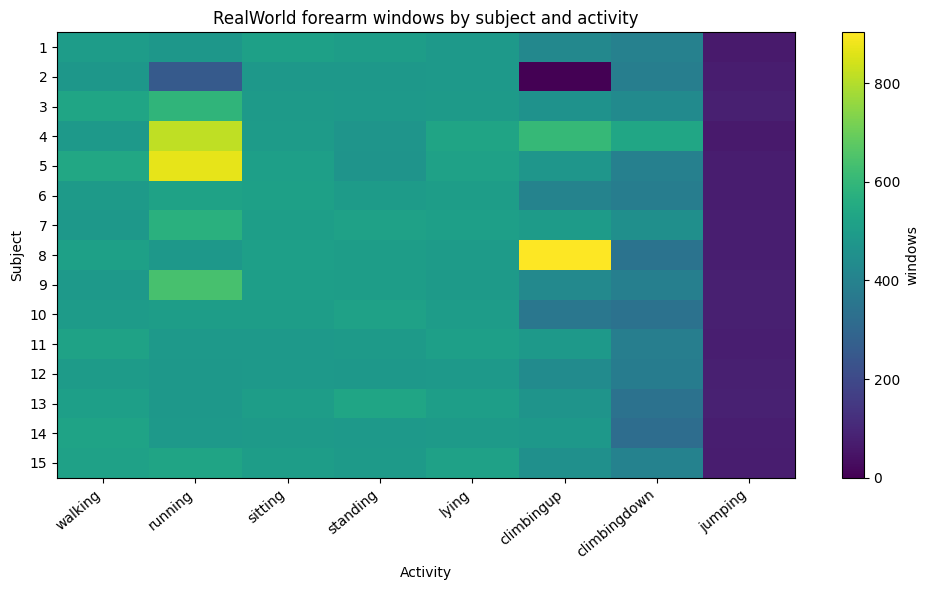

In [7]:
counts=pd.crosstab(pd.Series(window_subject,name='subject'),pd.Series(window_activity,name='activity')).reindex(index=CFG.subjects,columns=CFG.activities,fill_value=0)
counts.to_csv(OUT/'phase3a_window_counts.csv');display(counts)
expected_mask=pd.DataFrame(False,index=CFG.subjects,columns=CFG.activities)
for subject,activity in EXPECTED_MISSING:expected_mask.loc[subject,activity]=True
coverage_ok=bool((((counts>0) & ~expected_mask) | ((counts==0) & expected_mask)).all().all())
positive_counts=counts.where(counts>0).stack()

acc_cache=np.load(CACHE/'realworld_forearm_acc_w128_s64_50hz.npz');multi_cache=np.load(CACHE/'realworld_forearm_accgyr_w128_s64_50hz.npz')
fold_valid=True
for fold in folds:
    sets=[set(fold[k]) for k in ('train_subjects','selection_subjects','integration_subjects','test_subjects')]
    pairwise=all(sets[i].isdisjoint(sets[j]) for i in range(len(sets)) for j in range(i+1,len(sets)))
    fold_valid=fold_valid and set.union(*sets)==set(CFG.subjects) and pairwise and sum(len(v) for v in sets)==15
gates={
 'G1_all_15_subjects_present':set(np.unique(window_subject))==set(CFG.subjects),
 'G2_all_8_activities_present':set(np.unique(window_activity))==set(CFG.activities),
 'G3_available_grid_and_expected_omission':coverage_ok and len(expected_omissions)==len(EXPECTED_MISSING),
 'G4_minimum_windows_on_available_recordings':bool(positive_counts.min()>=CFG.minimum_windows_per_subject_activity),
 'G5_accelerometer_cache_finite':bool(np.isfinite(acc_windows).all()),
 'G6_multimodal_cache_finite':bool(len(multimodal_windows)>0 and np.isfinite(multimodal_windows).all()),
 'G7_cache_shapes':bool(acc_windows.shape[1:]==(4,CFG.window_size) and multimodal_windows.shape[1:]==(7,CFG.window_size)),
 'G8_cache_roundtrip':bool(acc_cache['x'].shape==acc_windows.shape and multi_cache['x'].shape==multimodal_windows.shape),
 'G9_preregistered_folds_valid':bool(fold_valid),
 'G10_download_complete_and_no_unexpected_primary_failure':bool(len(download_manifest)==len(CFG.subjects)*len(CFG.activities)*len(CFG.sensors) and not parse_failures),
 'G11_secondary_exclusions_documented':bool(len(secondary_exclusions)==0)}

quality={'phase':'Phase 3A','dataset':'RealWorld HAR','gates':gates,'proceed_to_phase3b':bool(all(gates.values())),
 'cache':{'accelerometer':str(CACHE/'realworld_forearm_acc_w128_s64_50hz.npz'),'accelerometer_shape':list(acc_windows.shape),
          'multimodal':str(CACHE/'realworld_forearm_accgyr_w128_s64_50hz.npz'),'multimodal_shape':list(multimodal_windows.shape)},
 'expected_omissions':expected_omissions,'secondary_exclusions':secondary_exclusions,
 'minimum_available_windows':int(positive_counts.min()),'maximum_windows':int(counts.max().max()),'total_windows':int(len(acc_windows)),
 'manifest':str(OUT/'phase3a_preregistered_manifest.json')}
(OUT/'phase3a_quality_decision.json').write_text(json.dumps(quality,indent=2));print(json.dumps(quality,indent=2))

fig,ax=plt.subplots(figsize=(10,6));image=ax.imshow(counts.values,aspect='auto',cmap='viridis');ax.set_xticks(range(len(counts.columns)),counts.columns,rotation=40,ha='right');ax.set_yticks(range(len(counts.index)),counts.index)
ax.set_xlabel('Activity');ax.set_ylabel('Subject');ax.set_title('RealWorld forearm windows by subject and activity');fig.colorbar(image,ax=ax,label='windows')
fig.tight_layout();fig.savefig(OUT/'phase3a_window_coverage.png',dpi=180,bbox_inches='tight');plt.show()


In [8]:
report=f"""# FedVocabHAR RealWorld Phase 3A Data Report

## Decision

**Proceed to Phase 3B:** {quality['proceed_to_phase3b']}

## Cache summary

- Subjects: {len(np.unique(window_subject))}
- Activities: {len(np.unique(window_activity))}
- Total windows: {len(acc_windows)}
- Minimum available subject/activity windows: {int(positive_counts.min())}
- Expected official-source omission: subject 2 climbing-up (no forearm file in either archive)
- Accelerometer cache shape: {tuple(acc_windows.shape)}
- Accelerometer-plus-gyroscope cache shape: {tuple(multimodal_windows.shape)}

## Gates

"""
for name,value in gates.items():report+=f'- {name}: **{value}**\n'
report+='\nThe vocabulary, folds, frozen Phase 2E method, and decision gates were preregistered before processing. Phase 3A performs no model training or hyperparameter selection.\n'
(OUT/'FedVocabHAR_RealWorld_Phase3A_Data_Report.md').write_text(report);print(report);print('saved outputs to',OUT)
assert quality['proceed_to_phase3b'],'Phase 3A quality gates failed; do not train Phase 3B'


# FedVocabHAR RealWorld Phase 3A Data Report

## Decision

**Proceed to Phase 3B:** True

## Cache summary

- Subjects: 15
- Activities: 8
- Total windows: 52098
- Minimum available subject/activity windows: 65
- Expected official-source omission: subject 2 climbing-up (no forearm file in either archive)
- Accelerometer cache shape: (52098, 4, 128)
- Accelerometer-plus-gyroscope cache shape: (51702, 7, 128)

## Gates

- G1_all_15_subjects_present: **True**
- G2_all_8_activities_present: **True**
- G3_available_grid_and_expected_omission: **True**
- G4_minimum_windows_on_available_recordings: **True**
- G5_accelerometer_cache_finite: **True**
- G6_multimodal_cache_finite: **True**
- G7_cache_shapes: **True**
- G8_cache_roundtrip: **True**
- G9_preregistered_folds_valid: **True**
- G10_download_complete_and_no_unexpected_primary_failure: **True**
- G11_secondary_exclusions_documented: **True**

The vocabulary, folds, frozen Phase 2E method, and decision gates were preregistered before pr

## Next step

If every data-quality gate passes, Phase 3B will run the frozen SSL-Full plus Episodic Anchor recipe inside each preregistered outer fold. The accelerometer cache is the primary experiment; accelerometer plus gyroscope is a secondary modality ablation. No Phase 3B result may change the manifest created by this notebook.
